In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
# data = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/refs/heads/master/chapter-02-car-price/data.csv'

In [3]:
# !wget $data

Load Data

In [4]:
df = pd.read_csv('data.csv')

In [5]:
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [6]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [7]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [8]:
strings = list(df.dtypes[df.dtypes == 'str'].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [9]:
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [10]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


## Exploratory data analysis 

In [11]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

make
<StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
48

model
<StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
914

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
<StringArray>
[   'premium_unleaded_(required)',               'regular_unleaded',
 'premium_unleaded_(recommended)',       'flex-fuel_(unleaded/e85)',
                         'diesel']
Length: 5, dtype: str
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
<StringArray>
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
Length: 5, dtype: str
5

driven_wheels
<StringArray>
['rear_wheel_drive', 'front_wheel_drive', 'all_wheel_drive',
 'four_wheel_drive']
Length: 4, dtype: str
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
<StringArray>
['factory_tuner,luxury,high-performance',
                    'luxury,performance',
               'luxury,high-pe

<Axes: xlabel='msrp', ylabel='Count'>

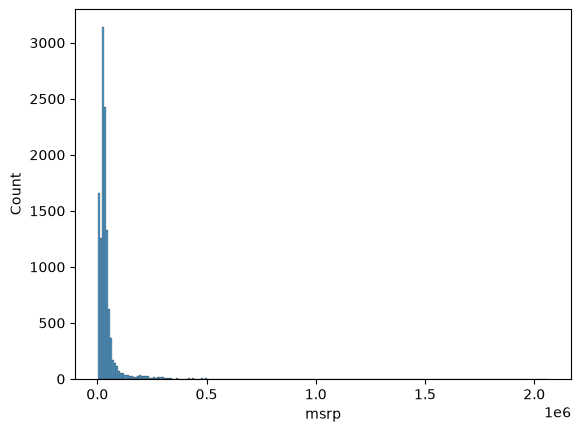

In [12]:
sns.histplot(df.msrp)

<Axes: xlabel='msrp', ylabel='Count'>

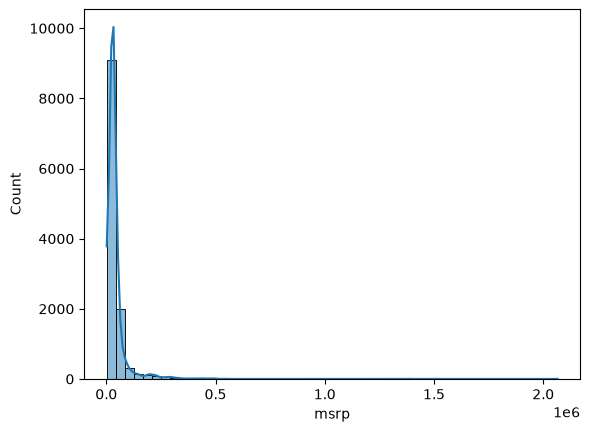

In [13]:
sns.histplot(df.msrp, bins=50, kde=True)
# this is a long tail distribution, so we can limit the x-axis to 100k to see the distribution better

<Axes: xlabel='msrp', ylabel='Count'>

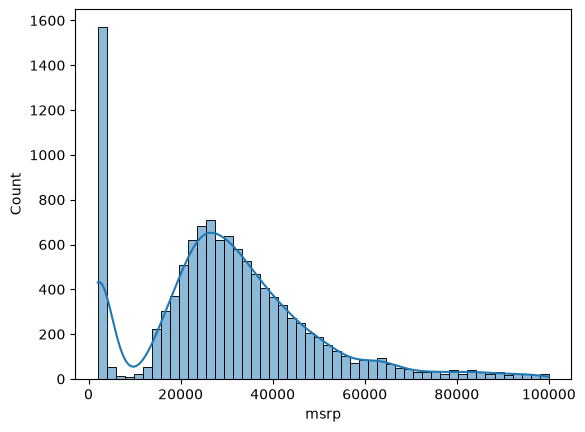

In [14]:
sns.histplot(df.msrp[df.msrp < 100000], bins=50, kde=True)
# We can see that the distribution is right-skewed, so we can apply a log transformation to make it more normal.

<Axes: xlabel='msrp', ylabel='Count'>

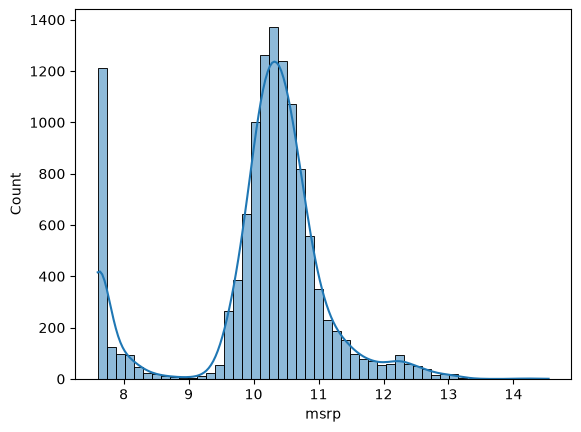

In [15]:
log_prices = np.log1p(df.msrp)
sns.histplot(log_prices, bins=50, kde=True)
# We can see that the distribution is now more normal, so we can use log_prices as our target variable.

In [16]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

## setting up vadidatipn framewok

In [17]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

In [18]:
n_train, n_val, n_test

(7150, 2382, 2382)

In [19]:
idx = np.arange(n)
np.random.seed(2)
np.random.shuffle(idx)

# shuffle the indices to ensure that the data is randomly distributed across the train, validation, and test sets.

In [20]:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]  

In [21]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
2735,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
6720,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
5878,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
11190,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4554,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260


In [22]:
len(df_train), len(df_val), len(df_test)

(7150, 2382, 2382)

In [23]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [24]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values) 

In [25]:
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

# delete the target variable from the dataframes to avoid data leakage during model training and evaluation.

## linear regression

In [26]:
df_train.iloc[10]

make                                 rolls-royce
model                     phantom_drophead_coupe
year                                        2015
engine_fuel_type     premium_unleaded_(required)
engine_hp                                  453.0
engine_cylinders                            12.0
transmission_type                      automatic
driven_wheels                   rear_wheel_drive
number_of_doors                              2.0
market_category        exotic,luxury,performance
vehicle_size                               large
vehicle_style                        convertible
highway_mpg                                   19
city_mpg                                      11
popularity                                    86
Name: 10, dtype: object

In [27]:
# we are selecting engine_hp,city_mpg and popularity for this example. linear regression formula g(xi) = w0 + w1*xi1 + w2*xi2 + w3*xi3, where xi1 = engine_hp, xi2 = city_mpg, xi3 = popularity
xi = [435, 11, 86]

In [28]:
# w is the weight vector that we will learn during training. We will initialize it with random values.
w0 = 7.17
w = [0.01, 0.04, 0.002]

In [29]:
def linear_regression(xi):
    n = len(xi)

    pred = w0
    for i in range(n):
        pred = pred + w[i] * xi[i]
    return pred

In [30]:
linear_regression(xi)

12.132

In [31]:
np.expm1(12.123).round(2)

np.float64(184055.86)

## Linear Regression: Vector form

In [32]:
def dot(xi, w):
    n = len(xi)
    result = 0.0
    for i in range(n):
        result += xi[i] * w[i]
    return result

In [33]:
w_new = [w0] + w

In [34]:
def linear_regression(xi):
    xi = [1] + xi  # add the bias term to the input vector
    return dot(xi, w_new)

In [35]:
linear_regression(xi)

12.132

In [36]:
x1 = [1, 148, 24, 1385]
x2 = [1, 132, 25, 2031]
x10 = [1, 435, 11, 86]

X = np.array([x1, x2, x10])
X

array([[   1,  148,   24, 1385],
       [   1,  132,   25, 2031],
       [   1,  435,   11,   86]])

In [37]:
# multiplying the matrix X with the weight vector w_new to get the predictions for all three examples at once.
X.dot(w_new)

array([12.38 , 13.552, 12.132])

In [38]:
def linear_regression(X):
    return X.dot(w_new)

In [39]:
linear_regression(X)

array([12.38 , 13.552, 12.132])

## Train Linear Regression model

In [40]:
def train_linear_regression(X, y):
    pass

In [41]:
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [435, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38, 54, 185],
    [142, 25, 431],
    [453, 31, 86]    
]

X = np.array(X)
X

array([[ 148,   24, 1385],
       [ 132,   25, 2031],
       [ 435,   11,   86],
       [ 158,   24,  185],
       [ 172,   25,  201],
       [ 413,   11,   86],
       [  38,   54,  185],
       [ 142,   25,  431],
       [ 453,   31,   86]])

In [42]:
ones = np.ones(X.shape[0])
ones

array([1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [43]:
# add a column of ones to the input matrix X to account for the bias term in the linear regression model. 
# This allows us to represent the bias term as a weight in the weight vector, which simplifies the calculations 
# and allows us to use matrix multiplication to compute the predictions.
X = np.column_stack([ones, X])

In [44]:
# y is the target variable, which contains the actual values of the dependent variable that 
# we are trying to predict using our linear regression model.
y = [100, 200, 150, 250, 100, 200, 150, 250, 120]

In [45]:
# gram matrix is a square matrix that contains the inner products of all pairs of vectors in a given set. 
# In this case, we are calculating the gram matrix for the input matrix X, which contains the features of our training examples. 
# The gram matrix is useful in linear regression because it allows us to compute the weights of the model using the normal equation.
XTX = X.T.dot(X)

In [46]:
# this is the inverse of the gram matrix, which is used in the normal equation to compute the weights of the linear regression model.
XTX_inv = np.linalg.inv(XTX)

In [47]:
XTX.dot(XTX_inv)

array([[ 1.00000000e+00,  4.85180472e-18,  1.09097844e-17,
         1.35842909e-18],
       [ 1.36221590e-12,  1.00000000e+00, -2.80472260e-14,
        -1.22199749e-16],
       [-3.07778976e-14,  1.04469656e-16,  1.00000000e+00,
        -9.74696694e-18],
       [ 2.05936830e-13,  2.62825514e-15, -8.66312095e-15,
         1.00000000e+00]])

In [48]:
w_full = XTX_inv.dot(X.T).dot(y)

In [49]:
w0 = w_full[0]
w = w_full[1:]

In [50]:
w0, w

(np.float64(297.6867526515406), array([-0.22673742, -2.52204291, -0.02245572]))

In [51]:
# this function takes in the input matrix X and the target variable y, and returns the weights of the linear regression model.
# def train_linear_regression(X, y):
#     ones = np.ones(X.shape[0])
#     X = np.column_stack([ones, X])

#     XTX = X.T.dot(X)
#     XTX_inv = np.linalg.inv(XTX)
#     w_full = XTX_inv.dot(X.T).dot(y)
    
#     return w_full[0], w_full[1:]

In [52]:
# # with call the additional column of ones inside the function, we can pass in the original input matrix X without having to modify it beforehand.
# w0, w = train_linear_regression(X[:, 1:], y)
# w0, w

In [53]:
def train_linear_regression(X, y):
    if not np.all(X[:, 0] == 1):
        X = np.column_stack([np.ones(len(X)), X])
    w, *_ = np.linalg.lstsq(X, y, rcond=None)
    return w[0], w[1:]

In [54]:
train_linear_regression(X, y)

(np.float64(297.68675265154025),
 array([-0.22673742, -2.52204291, -0.02245572]))

## Car price baseline model

In [55]:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='str')

In [56]:
base_features = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']
df_train[base_features].head()

,engine_hp,engine_cylinders,highway_mpg,city_mpg,popularity
0,148.0,4.0,33,24,1385
1,132.0,4.0,32,25,2031
2,148.0,4.0,37,28,640
3,90.0,4.0,18,16,873
4,385.0,8.0,21,15,5657


In [57]:
X_train = df_train[base_features].values
X_train

array([[ 148.,    4.,   33.,   24., 1385.],
       [ 132.,    4.,   32.,   25., 2031.],
       [ 148.,    4.,   37.,   28.,  640.],
       ...,
       [ 285.,    6.,   22.,   17.,  549.],
       [ 563.,   12.,   21.,   13.,   86.],
       [ 200.,    4.,   31.,   22.,  873.]], shape=(7150, 5))

In [106]:
median_values = df_train[base_features].median()
X_train = df_train[base_features].fillna(0).values

In [59]:
y_train

array([ 9.57574708,  9.887663  ,  9.89323518, ..., 10.45380308,
       12.62248099, 10.54061978], shape=(7150,))

In [60]:
w0, w = train_linear_regression(X_train, y_train)

In [61]:
y_pred = w0 + X_train.dot(w)

<Axes: ylabel='Count'>

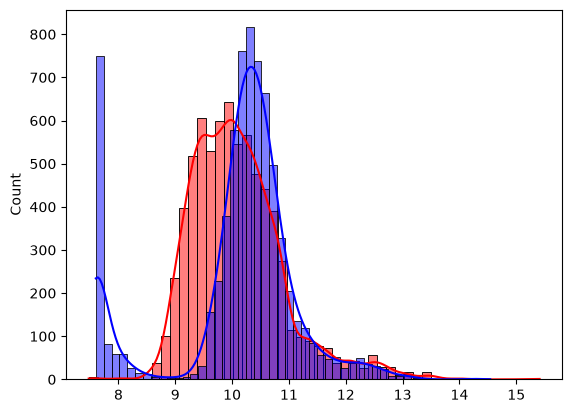

In [62]:
# plot the predicted values against the actual values to see how well the model is performing.
sns.histplot(y_pred, color='red', alpha=0.5, bins=50, kde=True)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50, kde=True)

## RMSE

In [63]:
# root mean squared error (RMSE) is a common metric used to evaluate the performance of regression models. 
# It measures the average difference between the predicted values and the actual values, with larger errors 
# being penalized more heavily than smaller errors. A lower RMSE indicates better model performance.
def rmse(y, y_pred):
    error = y - y_pred
    mse = (error ** 2).mean()
    return np.sqrt(mse)

In [64]:
rmse(y_train, y_pred)

np.float64(0.7554192603920132)

## Validating the model

In [65]:
# function to prepare the input matrix X for the linear regression model. 
# It takes in a dataframe df and returns a numpy array X containing the values 
# of the base features, with any missing values filled with the median.
median_values = df_train[base_features].median()
def prepare_X(df):
    df_num = df[base_features]
    df_num = df_num.fillna(median_values)
    X = df_num.values
    return X

In [66]:
# Prepare the training data
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

# Prepare the validation data
x_val = prepare_X(df_val)
y_pred = w0 + x_val.dot(w)

rmse(y_val, y_pred)

np.float64(0.7496401374569702)

## Simple feature engineering

In [67]:
def prepare_X(df):
    df = df.copy()
    df['age'] = 2017 - df['year']
    features = base_features + ['age']

    df_num = df[features]
    df_num = df_num.fillna(median_values)
    X = df_num.values
    return X

In [68]:
X_train = prepare_X(df_train)
# w0, w = train_linear_regression(X_train, y_train)

X_train

array([[1.480e+02, 4.000e+00, 3.300e+01, 2.400e+01, 1.385e+03, 9.000e+00],
       [1.320e+02, 4.000e+00, 3.200e+01, 2.500e+01, 2.031e+03, 5.000e+00],
       [1.480e+02, 4.000e+00, 3.700e+01, 2.800e+01, 6.400e+02, 1.000e+00],
       ...,
       [2.850e+02, 6.000e+00, 2.200e+01, 1.700e+01, 5.490e+02, 2.000e+00],
       [5.630e+02, 1.200e+01, 2.100e+01, 1.300e+01, 8.600e+01, 3.000e+00],
       [2.000e+02, 4.000e+00, 3.100e+01, 2.200e+01, 8.730e+02, 0.000e+00]],
      shape=(7150, 6))

In [69]:
# Prepare the training data
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

# Prepare the validation data
x_val = prepare_X(df_val)
y_pred = w0 + x_val.dot(w)

rmse(y_val, y_pred)

np.float64(0.5075020336888565)

<Axes: ylabel='Count'>

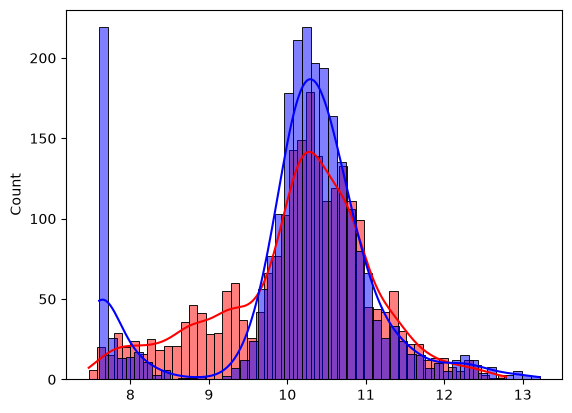

In [70]:
# plot the predicted values against the actual values to see how well the model is performing.
sns.histplot(y_pred, color='red', alpha=0.5, bins=50, kde=True)
sns.histplot(y_val, color='blue', alpha=0.5, bins=50, kde=True)

## Categorical Variables

In [71]:
(df_train.number_of_doors == 2).astype('int')

0       1
1       0
2       0
3       0
4       0
       ..
7145    1
7146    1
7147    0
7148    0
7149    0
Name: number_of_doors, Length: 7150, dtype: int64

In [72]:
for i in [2,3,4]:
    df_train['num_doors_%s' %i] = (df_train.number_of_doors == i).astype('int')

In [73]:
df_train.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,num_doors_2,num_doors_3,num_doors_4
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,1,0,0
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,0,0,1
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,0,0,1
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,0,1,0
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,0,0,1


In [74]:
def prepare_X(df):
    df = df.copy()
    df['age'] = 2017 - df['year']
    features = base_features.copy()
    features.append('age')

    for i in [2,3,4]:
        df['num_doors_%s' %i] = (df.number_of_doors == i).astype('int')
        features.append('num_doors_%s' %i)

    df_num = df[features]
    df_num = df_num.fillna(median_values)
    X = df_num.values
    return X

In [75]:
prepare_X(df_train)

array([[148.,   4.,  33., ...,   1.,   0.,   0.],
       [132.,   4.,  32., ...,   0.,   0.,   1.],
       [148.,   4.,  37., ...,   0.,   0.,   1.],
       ...,
       [285.,   6.,  22., ...,   0.,   0.,   1.],
       [563.,  12.,  21., ...,   0.,   0.,   1.],
       [200.,   4.,  31., ...,   0.,   0.,   1.]], shape=(7150, 9))

In [76]:
# Prepare the training data
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

# Prepare the validation data
x_val = prepare_X(df_val)
y_pred = w0 + x_val.dot(w)

rmse(y_val, y_pred)

np.float64(0.5064072783580025)

In [77]:
make = list(df.make.value_counts().head().index)

In [78]:
def prepare_X(df):
    df = df.copy()
    df['age'] = 2017 - df['year']
    features = base_features.copy()
    features.append('age')

    for i in [2,3,4]:
        df['num_doors_%s' %i] = (df.number_of_doors == i).astype('int')
        features.append('num_doors_%s' %i)

        
    for i in make:
        df['makes_%s' %i] = (df.make == i).astype('int')
        features.append('makes_%s' %i)

    df_num = df[features]
    df_num = df_num.fillna(median_values)
    X = df_num.values
    return X

In [79]:
# Prepare the training data
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

# Prepare the validation data
x_val = prepare_X(df_val)
y_pred = w0 + x_val.dot(w)

rmse(y_val, y_pred)

np.float64(0.4987496493279497)

In [80]:
df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [81]:
categorical_variables = [
    'make','engine_fuel_type', 'transmission_type', 'driven_wheels', 'market_category', 'vehicle_size', 'vehicle_style'
]

In [82]:
categories = {}

for c in categorical_variables:
    categories[c] = list(df_train[c].value_counts().head().index)

In [83]:
categories 

{'make': ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge'],
 'engine_fuel_type': ['regular_unleaded',
  'premium_unleaded_(required)',
  'premium_unleaded_(recommended)',
  'flex-fuel_(unleaded/e85)',
  'diesel'],
 'transmission_type': ['automatic',
  'manual',
  'automated_manual',
  'direct_drive',
  'unknown'],
 'driven_wheels': ['front_wheel_drive',
  'rear_wheel_drive',
  'all_wheel_drive',
  'four_wheel_drive'],
 'market_category': ['crossover',
  'flex_fuel',
  'luxury',
  'hatchback',
  'luxury,performance'],
 'vehicle_size': ['compact', 'midsize', 'large'],
 'vehicle_style': ['sedan',
  '4dr_suv',
  'coupe',
  'convertible',
  '4dr_hatchback']}

In [84]:
def prepare_X(df):
    df = df.copy()
    df['age'] = 2017 - df['year']
    features = base_features.copy()
    features.append('age')

    for i in [2,3,4]:
        df['num_doors_%s' %i] = (df.number_of_doors == i).astype('int')
        features.append('num_doors_%s' %i)

    for c, values in categories.items():
        for v in values:
            df['%s_%s' %(c, v)] = (df[c] == v).astype('int')
            features.append('%s_%s' %(c, v))    

    df_num = df[features]
    df_num = df_num.fillna(median_values)
    X = df_num.values
    return X

In [85]:
# Prepare the training data
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

# Prepare the validation data
x_val = prepare_X(df_val)
y_pred = w0 + x_val.dot(w)

rmse(y_val, y_pred)

np.float64(0.4551502096743786)

In [86]:
w0, w

(np.float64(6.178733077514214),
 array([ 1.89871789e-03,  1.07119192e-01, -4.90175057e-03, -5.68322717e-03,
        -4.91988590e-05, -9.56429053e-02, -7.27448981e-01, -8.35658294e-01,
        -5.75254356e-01, -4.03293183e-02,  1.69342095e-01,  1.33213069e-02,
        -9.99597999e-02, -1.07780738e-01, -4.20624869e-01,  9.55897424e-02,
        -2.93905168e-01, -5.01616833e-01, -5.30479160e-02,  1.14141974e+00,
         9.70578595e-01,  1.19879844e+00,  2.33236571e+00,  5.35570595e-01,
         1.58408693e+00,  1.50724737e+00,  1.57367972e+00,  1.51371905e+00,
        -8.46675656e-02,  4.84577564e-02, -4.30366479e-02, -5.07465987e-04,
        -3.06399012e-02,  2.14643969e+00,  2.03171519e+00,  2.00057820e+00,
        -4.76912209e-02,  5.68856318e-02,  1.51473983e-01,  3.28483264e-01,
        -1.52013644e-01]))

## Regularization

In [87]:
# Regularization is a technique used to prevent overfitting in machine learning models by adding a penalty term to the loss function.
# this helps to resolve the duplicate features problem, where multiple features are highly correlated and can lead to unstable weight estimates.

def train_linear_regression_reg(X, y, r=0.001):
    if not np.all(X[:, 0] == 1):
        X = np.column_stack([np.ones(len(X)), X])

    reg = r * np.eye(X.shape[1])
    reg[0, 0] = 0  # don't penalize the bias

    w = np.linalg.solve(X.T @ X + reg, X.T @ y)
    return w[0], w[1:]

In [88]:
# Prepare the training data
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r=0.01)

# Prepare the validation data
x_val = prepare_X(df_val)
y_pred = w0 + x_val.dot(w)

rmse(y_val, y_pred)

np.float64(0.4551508562104006)

In [89]:
# def train_linear_regression_reg(X, y, r=0.001):
#     ones = np.ones(X.shape[0])
#     X = np.column_stack([ones, X])

#     XTX = X.T.dot(X)
#     XTX += r * np.eye(XTX.shape[0])

#     XTX_inv = np.linalg.inv(XTX)
#     w_full = XTX_inv.dot(X.T).dot(y)
    
#     return w_full[0], w_full[1:]

In [90]:
# # Prepare the training data
# X_train = prepare_X(df_train)
# w0, w = train_linear_regression_reg(X_train, y_train, r=0.01)

# # Prepare the validation data
# x_val = prepare_X(df_val)
# y_pred = w0 + x_val.dot(w)

# rmse(y_val, y_pred)

## Tining the model

In [91]:
# Tuning the regularization parameter r can help to improve the performance of 
# the model by finding the optimal balance between bias and variance (i.e, the best value for r). 
# A smaller value of r will result in a model that is more flexible and can fit the training data better, 
# but may also overfit and perform poorly on new data. A larger value of r will result in a model that is more 
# constrained and may not fit the training data as well, but may generalize better to new data.
# Prepare the training data

for r in [0.0, 0.00001, 0.001,0.001, 0.01, 0.1, 1.0, 10]:

    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    # Prepare the validation data
    x_val = prepare_X(df_val)
    y_pred = w0 + x_val.dot(w)

    score = rmse(y_val, y_pred)

    print(r, w0, score)


0.0 -37.60364686859723 0.45515020967437375
1e-05 11.018731560230487 0.45515021032017644
0.001 11.018338179762086 0.4551502742615247
0.001 11.018338179762086 0.4551502742615247
0.01 11.014734559184365 0.4551508562104006
0.1 10.980398755767158 0.45515673961196346
1.0 10.746024755411586 0.4552215264761183
10 10.165418842805662 0.4561026341517373


In [92]:
r = 0.001
# Prepare the training data
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r=r)

# Prepare the validation data
x_val = prepare_X(df_val)
y_pred = w0 + x_val.dot(w)

score = rmse(y_val, y_pred)
print(score)

0.4551502742615247


## Using the model

In [93]:
df_full_train = pd.concat([df_train, df_val])

In [94]:
df_full_train = df_full_train.reset_index(drop=True)

In [95]:
X_full_train = prepare_X(df_full_train)

In [96]:
X_full_train

array([[148.,   4.,  33., ...,   1.,   0.,   0.],
       [132.,   4.,  32., ...,   0.,   0.,   1.],
       [148.,   4.,  37., ...,   0.,   0.,   1.],
       ...,
       [332.,   8.,  23., ...,   0.,   0.,   0.],
       [148.,   4.,  34., ...,   0.,   0.,   0.],
       [290.,   6.,  25., ...,   0.,   0.,   0.]], shape=(9532, 41))

In [97]:
y_full_train = np.concatenate([y_train, y_val])

In [98]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

In [99]:
# Prepare the validation data
x_test = prepare_X(df_test)
y_pred = w0 + x_test.dot(w)

score = rmse(y_test, y_pred)
print(score)

0.45130970246252006


In [100]:
car = df_test.iloc[20].to_dict()
car

{'make': 'toyota',
 'model': 'sienna',
 'year': 2015,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 266.0,
 'engine_cylinders': 6.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'front_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'large',
 'vehicle_style': 'passenger_minivan',
 'highway_mpg': 25,
 'city_mpg': 18,
 'popularity': 2031}

In [101]:
df_small = pd.DataFrame([car])
df_small

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,toyota,sienna,2015,regular_unleaded,266.0,6.0,automatic,front_wheel_drive,4.0,NaN,large,passenger_minivan,25,18,2031


In [102]:
X_small = prepare_X(df_small)

In [103]:
y_pred = w0 + X_small.dot(w)
y_pred = y_pred[0]
y_pred

np.float64(10.460284068290607)

In [104]:
np.expm1(y_pred).round(2)

np.float64(34900.46)

In [105]:
np.expm1(y_test[20]).round(2)

np.float64(35000.0)

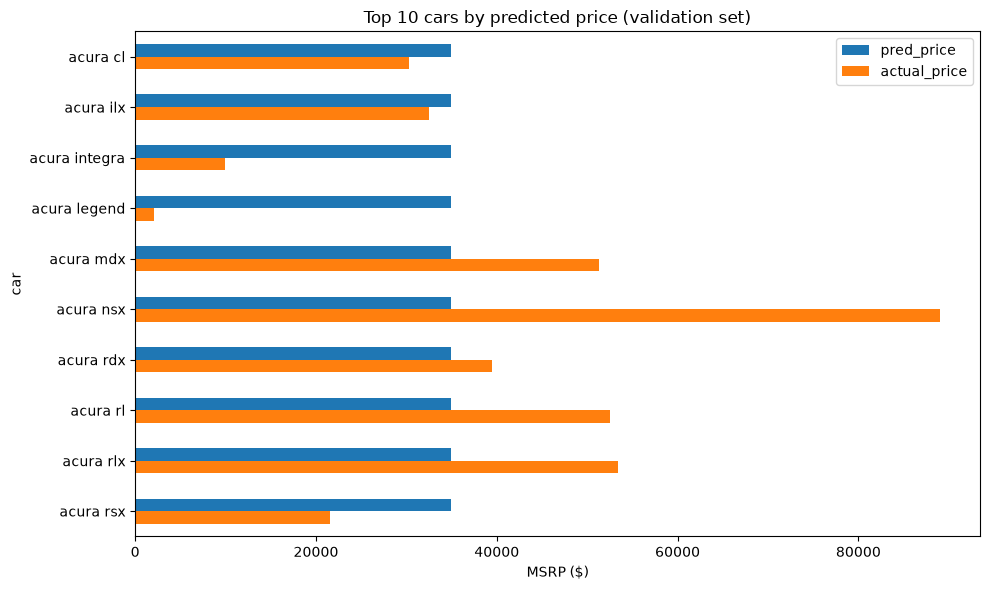

In [112]:
results = df_val.copy()
results['pred_price'] = np.expm1(y_pred)    # undo log1p
results['actual_price'] = np.expm1(y_val)
results['car'] = results['make'] + ' ' + results['model']

# average per car, since the same model appears many times (trims/years)
top10 = (results.groupby('car')[['pred_price', 'actual_price']]
                .mean()
                .nlargest(10, 'pred_price'))

ax = top10.plot.barh(figsize=(10, 6))
ax.invert_yaxis()                            # highest at the top
ax.set_xlabel('MSRP ($)')
ax.set_title('Top 10 cars by predicted price (validation set)')
plt.tight_layout()
plt.show()